In [3]:
from google.colab import drive, userdata
import os, sys
drive.mount('/content/drive')

TOKEN = userdata.get('GITHUB_TOKEN')
USER, REPO = "jeevithrao", "ML_AL_MC"
REPO_DIR = f"/content/{REPO}"
if not os.path.exists(REPO_DIR):
    !git clone https://{TOKEN}@github.com/{USER}/{REPO}.git {REPO_DIR}
%cd {REPO_DIR}
!git remote set-url origin https://{TOKEN}@github.com/{USER}/{REPO}.git
!git config user.name "jeevithrao"
!git config user.email "138958136+jeevithrao@users.noreply.github.com"
!git pull origin main
sys.path.append(f"{REPO_DIR}/src")
os.environ["PYTHONPATH"] = f"{REPO_DIR}/src"
print("repo present:", os.path.isdir(f"{REPO_DIR}/src"), "| Drive present:", os.path.isdir("/content/drive/MyDrive/birdclef_project"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cloning into '/content/ML_AL_MC'...
remote: Enumerating objects: 115, done.
remote: Counting objects: 100% (115/115), done.
remote: Compressing objects: 100% (98/98), done.
remote: Total 115 (delta 24), reused 103 (delta 12), pack-reused 0 (from 0)
Receiving objects: 100% (115/115), 10.36 MiB | 13.87 MiB/s, done.
Resolving deltas: 100% (24/24), done.
/content/ML_AL_MC
From https://github.com/jeevithrao/ML_AL_MC
 * branch            main       -> FETCH_HEAD
Already up to date.
repo present: True | Drive present: True


In [4]:
%%writefile /content/ML_AL_MC/src/final_eval.py
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_fscore_support, roc_curve)

def per_class_auc(Y, P):
    out = np.full(Y.shape[1], np.nan)
    for c in range(Y.shape[1]):
        pos = Y[:, c].sum()
        if 0 < pos < len(Y):
            out[c] = roc_auc_score(Y[:, c], P[:, c])
    return out

def metric_row(Y, P, thr):
    Yi, pred = Y.astype(int), (P > thr)
    n = np.arange(len(Y))
    top1 = P.argmax(1)
    top5 = np.argsort(-P, 1)[:, :5]
    auc = per_class_auc(Y, P)
    ap = [average_precision_score(Yi[:, c], P[:, c]) for c in range(Y.shape[1]) if Yi[:, c].sum() > 0]
    mp, mr, mf, _ = precision_recall_fscore_support(Yi, pred, average="macro", zero_division=0)
    _, _, uf, _ = precision_recall_fscore_support(Yi, pred, average="micro", zero_division=0)
    return {"threshold": round(float(thr), 2), "macro ROC-AUC": np.nanmean(auc), "macro mAP": np.mean(ap),
            "top-1 acc": Y[n, top1].mean(), "top-5 acc": Y[n[:, None], top5].max(1).mean(),
            "macro precision": mp, "macro recall": mr, "macro F1": mf, "micro F1": uf}

def best_threshold(Yv, Pv, grid=np.arange(0.05, 0.96, 0.05)):
    f = [precision_recall_fscore_support(Yv.astype(int), Pv > t, average="macro", zero_division=0)[2] for t in grid]
    return round(float(grid[int(np.argmax(f))]), 2), f, grid

def confusion_summary(prim_idx, P, Y, names, k_pairs=12, k_heat=15):
    top1 = P.argmax(1)
    wrong = Y[np.arange(len(Y)), top1] == 0          # top-1 is not any labelled species
    C = np.zeros((P.shape[1], P.shape[1]), int)
    np.add.at(C, (prim_idx[wrong], top1[wrong]), 1)
    pairs = pd.DataFrame([(names[i], names[j], int(C[i, j]), round(C[i, j] / max(1, (prim_idx == i).sum()), 3))
                          for i, j in zip(*np.nonzero(C))], columns=["true species", "predicted instead", "chunks", "share of true species' chunks"])
    pairs = pairs.sort_values("chunks", ascending=False).head(k_pairs).reset_index(drop=True)
    inv = C.sum(1) + C.sum(0)
    sel = np.argsort(-inv)[:k_heat]
    cnt = np.bincount(prim_idx, minlength=P.shape[1])
    M = C[np.ix_(sel, sel)] / np.maximum(cnt[sel][:, None], 1)
    return pairs, sel, M, float(wrong.mean())


def roc_figure(models, names, path, title="ROC curves on the test split"):
    """models: {label: (Y, P)}. One panel per model: micro-average plus the worst two, median and best species."""
    fig, axes = plt.subplots(1, len(models), figsize=(6.2 * len(models), 5), squeeze=False)
    for ax, (label, (Y, P)) in zip(axes[0], models.items()):
        auc = per_class_auc(Y, P)
        valid = np.where(~np.isnan(auc))[0]; srt = valid[np.argsort(auc[valid])]
        picks = [srt[0], srt[1], srt[len(srt) // 2], srt[-1]]
        fpr, tpr, _ = roc_curve(Y.ravel().astype(int), P.ravel())
        ax.plot(fpr, tpr, "k--", lw=1.6, label=f"micro-average (AUC {roc_auc_score(Y.ravel().astype(int), P.ravel()):.3f})")
        for c in picks:
            f, t, _ = roc_curve(Y[:, c].astype(int), P[:, c]); ax.plot(f, t, lw=1.3, label=f"{names[c]} (AUC {auc[c]:.3f})")
        ax.plot([0, 1], [0, 1], ":", c="gray", lw=1)
        ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
        ax.set_title(f"{label}\nmacro AUC {np.nanmean(auc):.4f}", fontsize=10); ax.legend(fontsize=7, loc="lower right"); ax.grid(alpha=.3)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(path, dpi=140); return fig

def confusion_figure(M, sel, names, path, title="Most-confused species (test split, row-normalised)"):
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    im = ax.imshow(M, cmap="Blues", vmin=0, vmax=max(0.3, float(M.max())))
    lab = [names[i] for i in sel]
    ax.set_xticks(range(len(sel))); ax.set_xticklabels(lab, rotation=75, ha="right", fontsize=7)
    ax.set_yticks(range(len(sel))); ax.set_yticklabels(lab, fontsize=7)
    ax.set_xlabel("predicted (top-1)"); ax.set_ylabel("true primary species"); ax.set_title(title, fontsize=10)
    fig.colorbar(im, ax=ax, fraction=0.046, label="share of the true species' chunks"); fig.tight_layout(); fig.savefig(path, dpi=140); return fig

def f1_figure(Y, P, thr, ntr, path):
    _, _, f1, sup = precision_recall_fscore_support(Y.astype(int), P > thr, average=None, zero_division=0)
    rare = ntr <= np.quantile(ntr, 0.25)
    fig, ax = plt.subplots(figsize=(6, 4.2))
    ax.scatter(ntr[~rare], f1[~rare], s=14, label="other species"); ax.scatter(ntr[rare], f1[rare], s=18, c="C3", label="rare (bottom 25% by training chunks)")
    ax.set_xscale("log"); ax.set_xlabel("training chunks per species"); ax.set_ylabel(f"test F1 at threshold {thr:.2f}")
    ax.set_title("Per-species F1 vs amount of training data", fontsize=10); ax.legend(fontsize=8); ax.grid(alpha=.3)
    fig.tight_layout(); fig.savefig(path, dpi=140)
    return dict(f1_rare=float(f1[rare].mean()), f1_other=float(f1[~rare].mean()), n_rare=int(rare.sum()))

Writing /content/ML_AL_MC/src/final_eval.py


In [6]:
import os, sys, json
SRC, DRV = "/content/ML_AL_MC/src", "/content/drive/MyDrive/birdclef_project"
assert os.path.isdir(SRC) and os.path.isdir(DRV), "Run the setup cell first (repo and Drive)"
if SRC not in sys.path: sys.path.append(SRC)
os.environ["PYTHONPATH"] = SRC
!pip install -q onnxruntime scikit-learn timm
TAR = f"{DRV}/mels.tar"
assert os.path.exists(TAR), "mels.tar missing on Drive"
if not os.path.exists("/content/data/mels"):
    !mkdir -p /content/data
    !tar -xf {TAR} -C /content/data
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from data_prep import prepare
from data_utils import MelDataset
from onnx_tools import ort_scores
from final_eval import *

idx, Y, rows, CLASSES, ALL = prepare()
names = json.load(open("/content/ML_AL_MC/docs/data/names.json"))
Yv, Yt = Y[rows["val"]], Y[rows["test"]]
MODELS = {"EfficientNet-B0 (teacher)": f"{DRV}/export/b0_fp32.onnx",
          "MobileNetV3-small (distilled student)": f"{DRV}/export/student_fp32.onnx"}
for p in MODELS.values():
    assert os.path.exists(p), f"{p} missing: re-run Cell 6.1a to recreate the ONNX files"

PRED = f"{DRV}/final_eval_preds.npz"
if os.path.exists(PRED):
    z = np.load(PRED); preds = {k: (z[f"v{i}"], z[f"t{i}"]) for i, k in enumerate(MODELS)}
    print("loaded saved predictions")
else:
    val_ds, test_ds = MelDataset(ALL, rows["val"], Y), MelDataset(ALL, rows["test"], Y)
    preds = {}
    for k, p in MODELS.items():
        preds[k] = (ort_scores(p, val_ds), ort_scores(p, test_ds)); print(k, "scored")
    np.savez_compressed(PRED, **{f"{pre}{i}": preds[k][j] for i, k in enumerate(MODELS) for j, pre in enumerate(["v", "t"])})

  0%|          | 0/24459 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


EfficientNet-B0 (teacher) scored
MobileNetV3-small (distilled student) scored


In [7]:
out = []
for k, (Pv, Pt) in preds.items():
    thr_k = best_threshold(Yv, Pv)[0]
    for rule, thr in [("fixed 0.5", 0.5), ("tuned on validation", thr_k)]:
        out.append({"model": k, "threshold rule": rule, **metric_row(Yt, Pt, thr)})
T = pd.DataFrame(out); display(T.round(4)); T.to_csv("/content/ML_AL_MC/results/final_metrics.csv", index=False)

,model,threshold rule,threshold,macro ROC-AUC,macro mAP,top-1 acc,top-5 acc,macro precision,macro recall,macro F1,micro F1
0,EfficientNet-B0 (teacher),fixed 0.5,0.50,0.9653,0.6321,0.7430,0.8783,0.7387,0.5277,0.5978,0.7171
1,EfficientNet-B0 (teacher),tuned on validation,0.35,0.9653,0.6321,0.7430,0.8783,0.6853,0.5715,0.6072,0.7185
2,MobileNetV3-small (distilled student),fixed 0.5,0.50,0.9634,0.6046,0.7062,0.8630,0.7367,0.4645,0.5464,0.6739
3,MobileNetV3-small (distilled student),tuned on validation,0.30,0.9634,0.6046,0.7062,0.8630,0.6720,0.5323,0.5768,0.6850


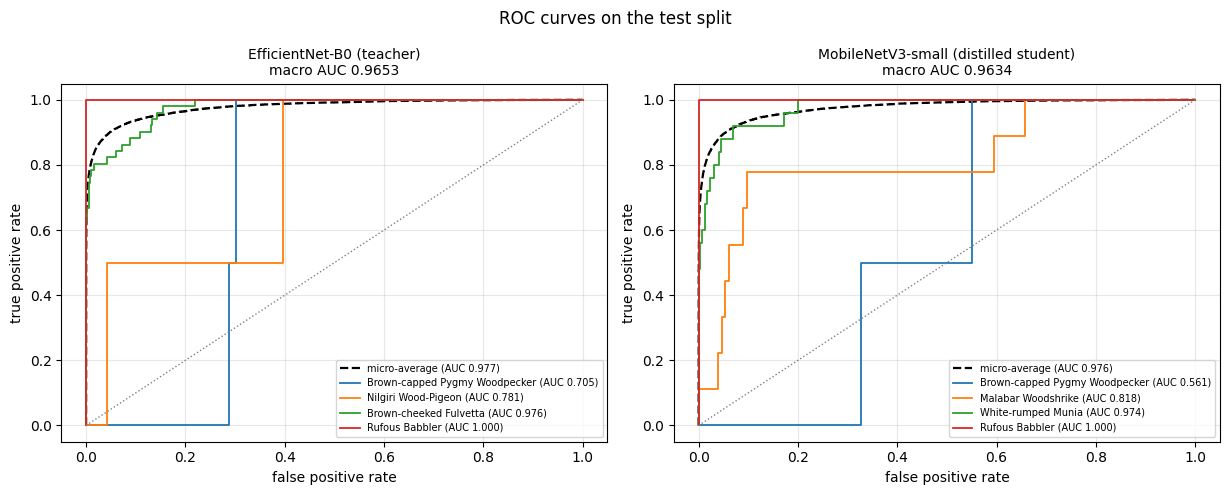

student top-1 error rate on test: 0.294


,true species,predicted instead,chunks,share of true species' chunks
0,Purple Heron,Gray Heron,23,0.223
1,Eurasian Coot,Little Grebe,12,0.064
2,Greenish Warbler,Green Warbler,12,0.056
3,Eurasian Moorhen,Eurasian Coot,11,0.063
4,Green Sandpiper,Little Grebe,11,0.057
5,Common Tailorbird,Little Spiderhunter,11,0.089
6,Little Egret,Black-crowned Night-Heron,11,0.075
7,Common Iora,Puff-throated Babbler,11,0.115
8,Little Grebe,Green Sandpiper,10,0.052
9,Green Warbler,Greenish Warbler,10,0.172


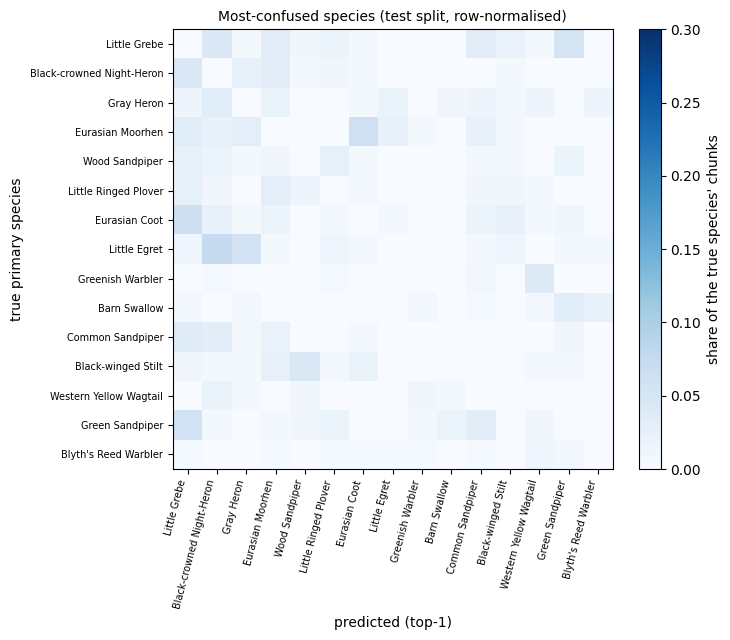

{'f1_rare': 0.41504656903708004, 'f1_other': 0.6330679858022636, 'n_rare': 47}


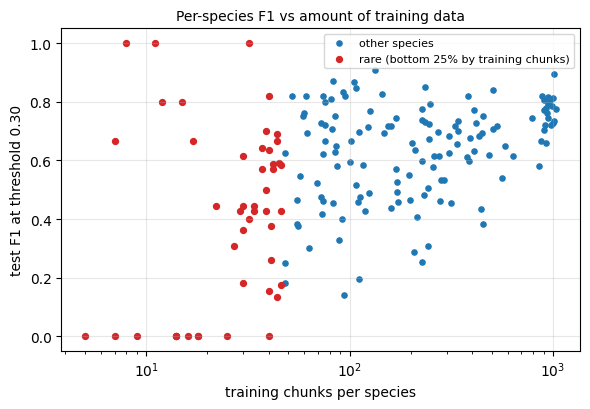

In [8]:
T_, S_ = list(MODELS)
roc_figure({k: (Yt, preds[k][1]) for k in MODELS}, names, "/content/ML_AL_MC/results/roc_curves.png"); plt.show()

cid = {c: i for i, c in enumerate(CLASSES)}
prim = np.array([cid[p] for p in idx.primary_label.values[rows["test"]]])
pairs, sel, M, err = confusion_summary(prim, preds[S_][1], Yt, names)
print(f"student top-1 error rate on test: {err:.3f}"); display(pairs)
pairs.to_csv("/content/ML_AL_MC/results/top_confusions.csv", index=False)
confusion_figure(M, sel, names, "/content/ML_AL_MC/results/confusion_top15.png"); plt.show()

ntr = pd.Series(idx.primary_label.values[rows["train"]]).value_counts().reindex(CLASSES).values
print(f1_figure(Yt, preds[S_][1], best_threshold(Yv, preds[S_][0])[0], ntr, "/content/ML_AL_MC/results/f1_vs_train_size.png")); plt.show()

In [9]:
p = "/content/ML_AL_MC/README.md"
s = open(p, encoding="utf-8").read()
s = s.replace("(see section 5)", "(download links in section 11)")
s += """
## 11. Resources for evaluators (large files are not in Git)
- GitHub repository: https://github.com/jeevithrao/ML_AL_MC
- Live demo: https://jeevithrao.github.io/ML_AL_MC/
- Google Drive folder (shared with the instructor): https://drive.google.com/drive/folders/1QqTkX97V40NsMkjmBe8fDgNYfWXJ0idQ?usp=sharing
  - mels.tar (5 GB): preprocessed spectrograms, restored automatically by the notebooks
  - checkpoints/: baseline_best.pt (EfficientNet-B0), mnv3s_kd_T2_a05_best.pt (distilled student) and the other student checkpoints
  - al_runs/: active learning run files (also copied to results/al in this repository)
  - export/: ONNX models (b0_fp32.onnx, student_fp32.onnx)
- Dataset: BirdCLEF 2024 on Kaggle, https://www.kaggle.com/c/birdclef-2024 (join the competition and accept its rules to download)
"""
open(p, "w", encoding="utf-8").write(s)

11758

In [ ]:
%cd /content/ML_AL_MC
!cp "/content/drive/MyDrive/Colab Notebooks/07_final_evaluation.ipynb" notebooks/07_final_evaluation.ipynb
!grep -rlE "ghp_|github_pat_|gho_|ghs_|KGAT_" notebooks src results docs README.md || echo "no tokens found"
!git add README.md requirements.txt src results notebooks
!git status --short
!git commit -m "Final evaluation (accuracy, precision, recall, F1, ROC), resources links in README"
!git push
